Lista 3 de Exercícios — Métodos Numéricos

Disciplina: Métodos Numéricos — 2026.2 Professor: Thales Vieira — Instituto de Computação, UFAL Curso: Engenharia de Computação Dupla: Thiego Macena e Davi Celestino Repositório: https://github.com/Davicsb/numerical-methods-studies

Questão 1

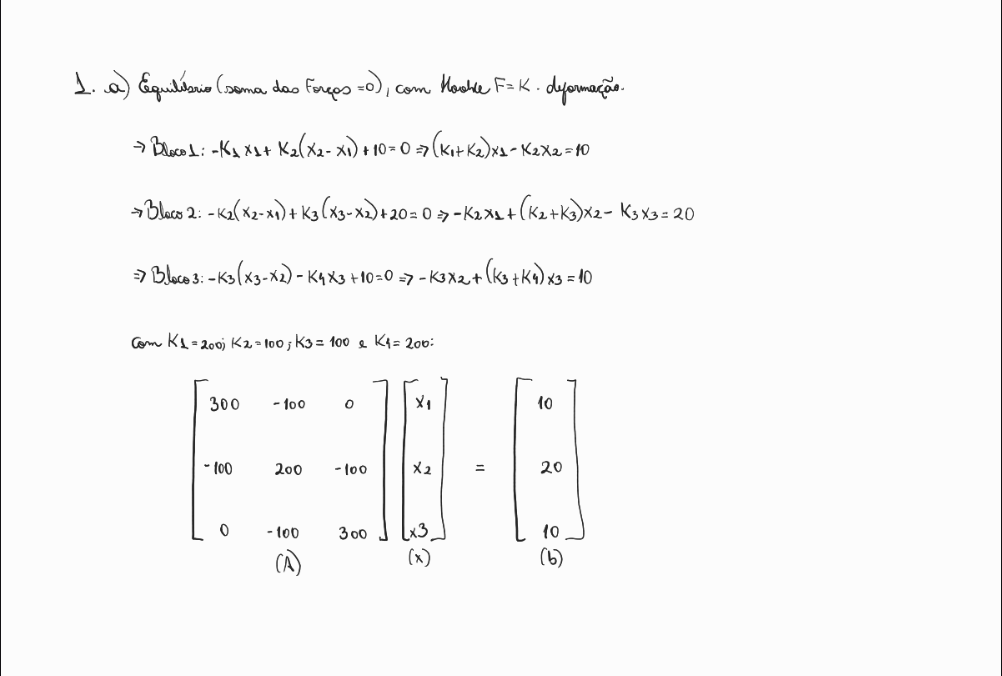

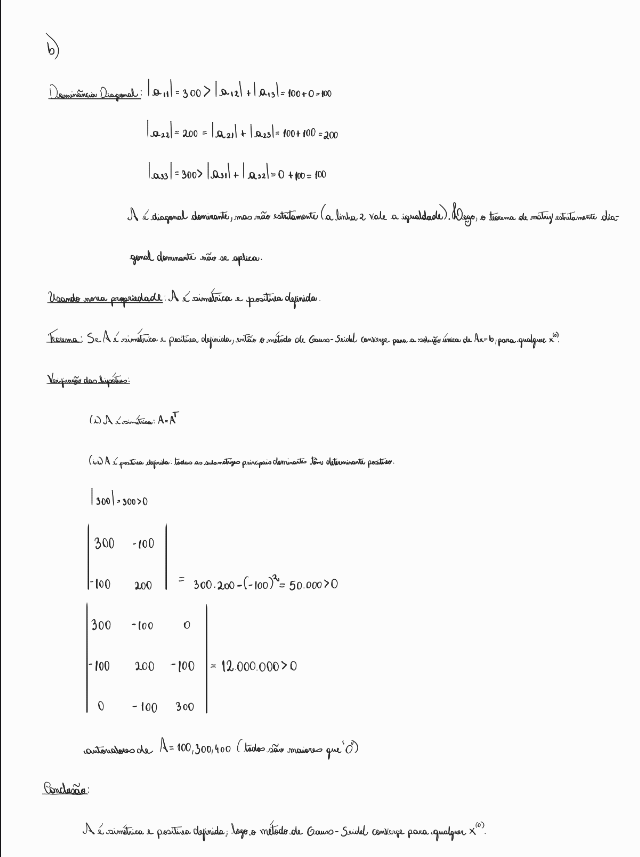

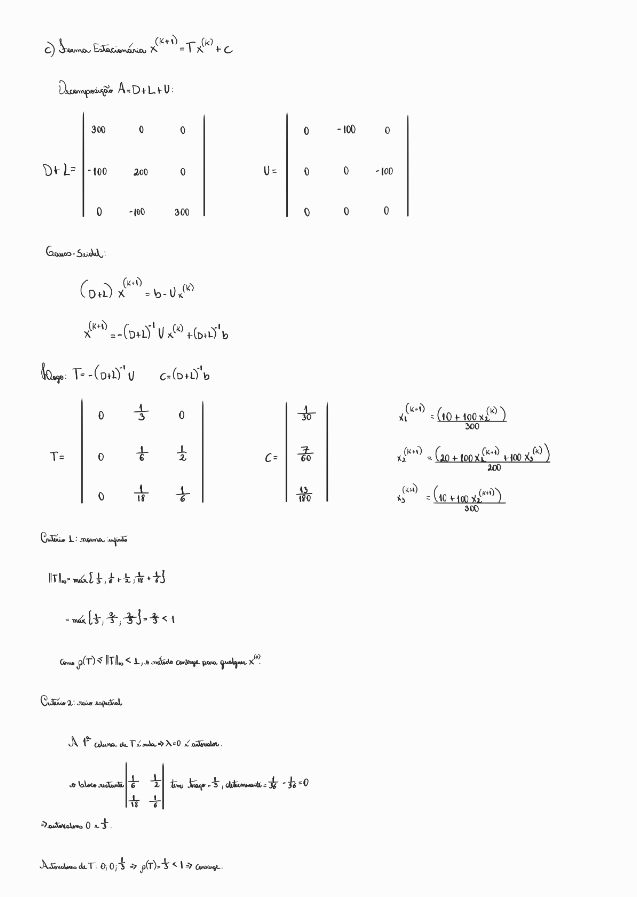

In [ ]:
# Questão 1 - Lista 3 - Métodos Numéricos
# Sistema de molas resolvido por Gauss-Seidel

k1, k2, k3, k4 = 200.0, 100.0, 100.0, 200.0
A = [[k1 + k2, -k2, 0.0],
     [-k2, k2 + k3, -k3],
     [0.0, -k3, k3 + k4]]
b = [10.0, 20.0, 10.0]
n = 3


def gauss_seidel(A, b, x0, tol=1e-5, max_iter=1000):
    n = len(b)
    x = x0[:]
    for k in range(1, max_iter + 1):
        x_old = x[:]
        for i in range(n):
            soma = 0.0
            for j in range(n):
                if j != i:
                    soma += A[i][j] * x[j]  # usa x já atualizado (j < i)
            x[i] = (b[i] - soma) / A[i][i]
        erro = max(abs(x[i] - x_old[i]) for i in range(n))
        print(f"k={k:3d}  x=({x[0]:.8f}, {x[1]:.8f}, {x[2]:.8f})  erro_inf={erro:.3e}")
        if erro < tol:
            return x, k, True
    return x, max_iter, False


# Solução exata por eliminação gaussiana (apenas para conferência)
def eliminacao(A, b):
    n = len(b)
    M = [A[i][:] + [b[i]] for i in range(n)]
    for i in range(n):
        for r in range(i + 1, n):
            f = M[r][i] / M[i][i]
            for c in range(i, n + 1):
                M[r][c] -= f * M[i][c]
    x = [0.0] * n
    for i in range(n - 1, -1, -1):
        x[i] = (M[i][n] - sum(M[i][j] * x[j] for j in range(i + 1, n))) / M[i][i]
    return x


# Matriz de iteração T = -(D+L)^-1 U e c = (D+L)^-1 b
def matriz_T_c(A, b):
    n = len(b)
    # resolve (D+L) y = coluna, por substituição direta
    def sub_direta(col):
        y = [0.0] * n
        for i in range(n):
            y[i] = (col[i] - sum(A[i][j] * y[j] for j in range(i))) / A[i][i]
        return y
    U = [[A[i][j] if j > i else 0.0 for j in range(n)] for i in range(n)]
    cols = [sub_direta([-U[i][j] for i in range(n)]) for j in range(n)]
    T = [[cols[j][i] for j in range(n)] for i in range(n)]
    c = sub_direta(b)
    return T, c


if __name__ == "__main__":
    print("=== Gauss-Seidel ===")
    x, k, ok = gauss_seidel(A, b, [0.0, 0.0, 0.0])
    if ok:
        print(f"\nConvergiu em {k} iterações")
    else:
        print("\nCRITÉRIO DE PARADA NÃO ATINGIDO em 1000 iterações")
    print("x (Gauss-Seidel) =", x)
    print("x (eliminação)   =", eliminacao(A, b))
    T, c = matriz_T_c(A, b)
    print("\nT =")
    for l in T:
        print(["%.6f" % v for v in l])
    print("c =", ["%.6f" % v for v in c])
    print("||T||_inf =", max(sum(abs(v) for v in l) for l in T))

=== Gauss-Seidel ===
k=  1  x=(0.03333333, 0.11666667, 0.07222222)  erro_inf=1.167e-01
k=  2  x=(0.07222222, 0.17222222, 0.09074074)  erro_inf=5.556e-02
k=  3  x=(0.09074074, 0.19074074, 0.09691358)  erro_inf=1.852e-02
k=  4  x=(0.09691358, 0.19691358, 0.09897119)  erro_inf=6.173e-03
k=  5  x=(0.09897119, 0.19897119, 0.09965706)  erro_inf=2.058e-03
k=  6  x=(0.09965706, 0.19965706, 0.09988569)  erro_inf=6.859e-04
k=  7  x=(0.09988569, 0.19988569, 0.09996190)  erro_inf=2.286e-04
k=  8  x=(0.09996190, 0.19996190, 0.09998730)  erro_inf=7.621e-05
k=  9  x=(0.09998730, 0.19998730, 0.09999577)  erro_inf=2.540e-05
k= 10  x=(0.09999577, 0.19999577, 0.09999859)  erro_inf=8.468e-06

Convergiu em 10 iterações
x (Gauss-Seidel) = [0.09999576622804789, 0.19999576622804788, 0.09999858874268262]
x (eliminação)   = [0.09999999999999999, 0.19999999999999996, 0.1]

T =
['-0.000000', '0.333333', '-0.000000']
['-0.000000', '0.166667', '0.500000']
['-0.000000', '0.055556', '0.166667']
c = ['0.033333', '0.11

Questão 2

In [1]:
# Questão 2 - Lista 3 - Métodos Numéricos

# Dados do problema (partilhados por todas as questões)
h = [0.0, 0.5, 1.0, 1.5, 2.0]
V = [0.0, 620.0, 1480.0, 2570.0, 4020.0]
h_alvo = 1.25

# a) Método dos Mínimos Quadrados (Grau 2)
def minimos_quadrados(x_vals, y_vals):
    n = len(x_vals)
    sum_x = sum(x_vals)
    sum_x2 = sum(x**2 for x in x_vals)
    sum_x3 = sum(x**3 for x in x_vals)
    sum_x4 = sum(x**4 for x in x_vals)

    sum_y = sum(y_vals)
    sum_xy = sum(x_vals[i] * y_vals[i] for i in range(n))
    sum_x2y = sum((x_vals[i]**2) * y_vals[i] for i in range(n))

    # Matriz A e Vetor B (A * a = B)
    A = [
        [n,      sum_x,  sum_x2],
        [sum_x,  sum_x2, sum_x3],
        [sum_x2, sum_x3, sum_x4]
    ]
    B = [sum_y, sum_xy, sum_x2y]

    # Determinante de matriz 3x3
    def det3x3(M):
        return (M[0][0]*(M[1][1]*M[2][2] - M[1][2]*M[2][1]) -
                M[0][1]*(M[1][0]*M[2][2] - M[1][2]*M[2][0]) +
                M[0][2]*(M[1][0]*M[2][1] - M[1][1]*M[2][0]))

    # Substituição de coluna para a Regra de Cramer
    def replace_col(M, col_idx, V_col):
        M_copy = [row[:] for row in M]
        for i in range(3):
            M_copy[i][col_idx] = V_col[i]
        return M_copy

    # Resolução por Regra de Cramer
    det_A = det3x3(A)
    a0 = det3x3(replace_col(A, 0, B)) / det_A
    a1 = det3x3(replace_col(A, 1, B)) / det_A
    a2 = det3x3(replace_col(A, 2, B)) / det_A

    return a0, a1, a2

# b) Interpolação de Lagrange (Grau 4)
def lagrange_interpolation(x_vals, y_vals, x_target):
    n = len(x_vals)
    y_target = 0.0

    for i in range(n):
        L_i = 1.0
        for j in range(n):
            if i != j:
                L_i *= (x_target - x_vals[j]) / (x_vals[i] - x_vals[j])
        y_target += y_vals[i] * L_i

    return y_target

# c) Método de Neville
def neville_method(x_vals, y_vals, x_target):
    n = len(x_vals)
    P = [[0.0 for _ in range(n)] for _ in range(n)]

    for i in range(n):
        P[i][0] = y_vals[i]

    for j in range(1, n):
        for i in range(j, n):
            termo1 = (x_target - x_vals[i - j]) * P[i][j - 1]
            termo2 = (x_target - x_vals[i]) * P[i - 1][j - 1]
            denominador = x_vals[i] - x_vals[i - j]
            P[i][j] = (termo1 - termo2) / denominador

    return P


# Execução e Apresentação dos Resultados
print("a) MÉTODO DOS MÍNIMOS QUADRADOS")
a0, a1, a2 = minimos_quadrados(h, V)
print(f"Coeficientes encontrados: a0 = {a0:.2f}, a1 = {a1:.2f}, a2 = {a2:.2f}")
print(f"Polinómio: p2(h) = {a0:.2f} + {a1:.2f}h + {a2:.2f}h^2")
v_estimado_mq = a0 + a1*h_alvo + a2*(h_alvo**2)
print(f"Volume estimado na curva para h = {h_alvo}m: {v_estimado_mq:.2f} L")

print()
print("b) INTERPOLAÇÃO DE LAGRANGE")
vol_lagrange = lagrange_interpolation(h, V, h_alvo)
print(f"Volume interpolado para h = {h_alvo}m: {vol_lagrange:.5f} L")

print()
print("c) MÉTODO DE NEVILLE")
tabela_neville = neville_method(h, V, h_alvo)
n_pontos = len(h)

print(f"Tabela Triangular para h = {h_alvo}m:\n")
for i in range(n_pontos):
    linha = f"i={i} | h={h[i]:.1f} | "
    for j in range(i + 1):
        linha += f"{tabela_neville[i][j]:.3f} | "
    print(linha)

vol_neville = tabela_neville[n_pontos-1][n_pontos-1]
print(f"\nValor final estimado do Volume: {vol_neville:.5f} L")

a) MÉTODO DOS MÍNIMOS QUADRADOS
Coeficientes encontrados: a0 = 10.00, a1 = 918.00, a2 = 540.00
Polinómio: p2(h) = 10.00 + 918.00h + 540.00h^2
Volume estimado na curva para h = 1.25m: 2001.25 L

b) INTERPOLAÇÃO DE LAGRANGE
Volume interpolado para h = 1.25m: 1991.40625 L

c) MÉTODO DE NEVILLE
Tabela Triangular para h = 1.25m:

i=0 | h=0.0 | 0.000 | 
i=1 | h=0.5 | 620.000 | 1550.000 | 
i=2 | h=1.0 | 1480.000 | 1910.000 | 2000.000 | 
i=3 | h=1.5 | 2570.000 | 2025.000 | 1996.250 | 1996.875 | 
i=4 | h=2.0 | 4020.000 | 1845.000 | 1980.000 | 1988.125 | 1991.406 | 

Valor final estimado do Volume: 1991.40625 L


Questão 3

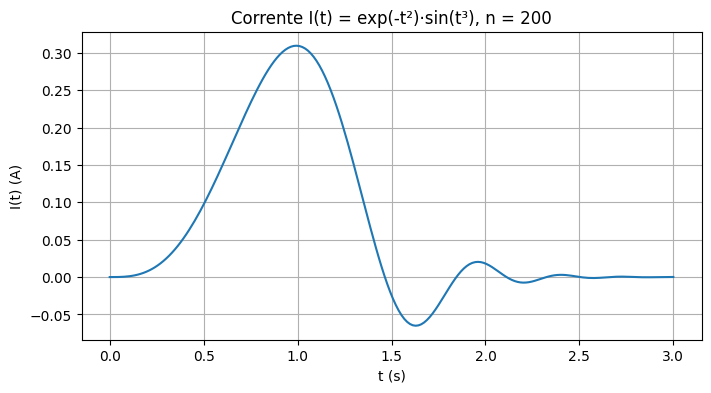

 i        t       I(t)      dI/dt
 0   0.0000   0.000000  -0.064983
 1   0.2143   0.009398   0.152697
 2   0.4286   0.065441   0.383319
 3   0.6429   0.173678   0.506430
 4   0.8571   0.282483   0.292493
 5   1.0714   0.299032  -0.279335
 6   1.2857   0.162768  -0.754623
 7   1.5000  -0.024378  -0.496811
 8   1.7143  -0.050151   0.100847
 9   1.9286   0.018842   0.107488
10   2.1429  -0.004085  -0.039405
11   2.3571   0.001954   0.006514
12   2.5714  -0.001293  -0.004196
13   2.7857   0.000156   0.003292
14   3.0000   0.000118  -0.003643

Maior taxa de crescimento (n=15): dI/dt = 0.506430 A/s em t = 0.6429 s


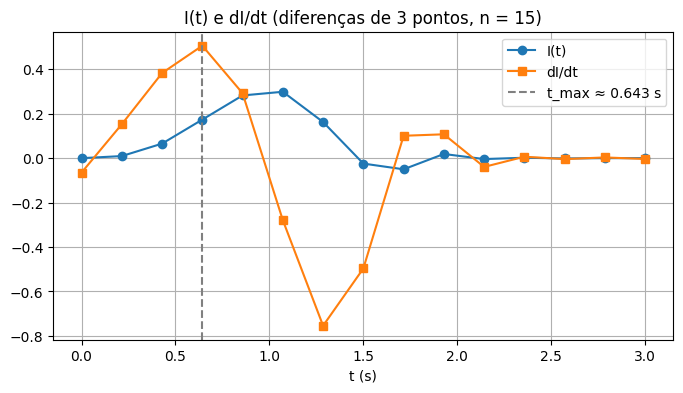

Conferência n=101: t_max = 0.6600 s, dI/dt = 0.5672 A/s
Conferência n=1001: t_max = 0.6540 s, dI/dt = 0.5686 A/s
  n          Q (C)
  2  -0.0486973639
  4   0.2153082160
  6   0.1578322488
  8   0.2173597427
 10   0.1935481023
 12   0.2000321436
 14   0.2017975543
 16   0.1998080446
 18   0.1996693631
 20   0.1999863625
 22   0.2001238591
 24   0.2001490828
 26   0.2001467066
 28   0.2001423994
 30   0.2001399003
 32   0.2001387188
 34   0.2001382033
 36   0.2001379952
 38   0.2001379259
 40   0.2001379185
 42   0.2001379376
 44   0.2001379670
 46   0.2001379989
 48   0.2001380298
 50   0.2001380583

Q (n = 50) = 0.20013806 C


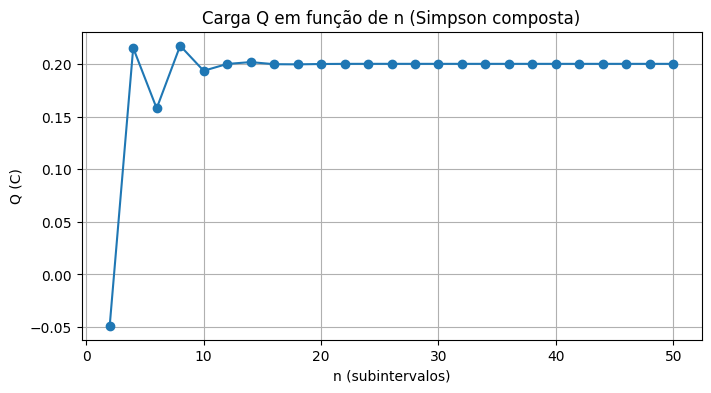

In [ ]:
# Questão 3 - Lista 3 - Métodos Numéricos
# I(t) = exp(-t^2) * sin(t^3): amostragem, derivada numérica e integral numérica

# ---------- a) amostragem do sinal ----------
import sympy as sp
import matplotlib.pyplot as plt


def amostrar(expr_str, a, b, n):
    """Recebe a string de I(t), o intervalo [a, b] e n amostras.
    Retorna as listas t e I(t), com n pontos igualmente espaçados."""
    t_sym = sp.Symbol("t")
    expr = sp.sympify(expr_str)
    h = (b - a) / (n - 1)
    t = [a + i * h for i in range(n)]
    I = [float(expr.subs(t_sym, ti)) for ti in t]
    return t, I


EXPR = "exp(-t**2)*sin(t**3)"

t200, I200 = amostrar(EXPR, 0.0, 3.0, 200)
plt.figure(figsize=(8, 4))
plt.plot(t200, I200)
plt.xlabel("t (s)")
plt.ylabel("I(t) (A)")
plt.title("Corrente I(t) = exp(-t²)·sin(t³), n = 200")
plt.grid(True)
plt.show()


# ---------- b) derivada por diferenças de 3 pontos ----------
def derivada_3pontos(t, I):
    """Diferenças de 3 pontos em malha uniforme:
    interior -> centrada;  extremos -> unilaterais de 3 pontos."""
    n = len(t)
    h = t[1] - t[0]
    d = [0.0] * n
    d[0] = (-3 * I[0] + 4 * I[1] - I[2]) / (2 * h)
    for i in range(1, n - 1):
        d[i] = (I[i + 1] - I[i - 1]) / (2 * h)
    d[n - 1] = (3 * I[n - 1] - 4 * I[n - 2] + I[n - 3]) / (2 * h)
    return d


t15, I15 = amostrar(EXPR, 0.0, 3.0, 15)
dI15 = derivada_3pontos(t15, I15)

print(f"{'i':>2} {'t':>8} {'I(t)':>10} {'dI/dt':>10}")
for i in range(15):
    print(f"{i:2d} {t15[i]:8.4f} {I15[i]:10.6f} {dI15[i]:10.6f}")

i_max = max(range(15), key=lambda i: dI15[i])
print(f"\nMaior taxa de crescimento (n=15): dI/dt = {dI15[i_max]:.6f} A/s em t = {t15[i_max]:.4f} s")

plt.figure(figsize=(8, 4))
plt.plot(t15, I15, "o-", label="I(t)")
plt.plot(t15, dI15, "s-", label="dI/dt")
plt.axvline(t15[i_max], color="gray", linestyle="--", label=f"t_max ≈ {t15[i_max]:.3f} s")
plt.xlabel("t (s)")
plt.title("I(t) e dI/dt (diferenças de 3 pontos, n = 15)")
plt.legend()
plt.grid(True)
plt.show()

# conferência com malhas mais finas
for n_ref in (101, 1001):
    tr, Ir = amostrar(EXPR, 0.0, 3.0, n_ref)
    dr = derivada_3pontos(tr, Ir)
    im = max(range(n_ref), key=lambda i: dr[i])
    print(f"Conferência n={n_ref}: t_max = {tr[im]:.4f} s, dI/dt = {dr[im]:.4f} A/s")


# ---------- c) integral por Simpson composta ----------
def simpson_composta(expr_str, a, b, n):
    """Simpson composta com n subintervalos (n par)."""
    if n % 2 != 0:
        raise ValueError("n deve ser par")
    t, I = amostrar(expr_str, a, b, n + 1)
    h = (b - a) / n
    soma = I[0] + I[n]
    for j in range(1, n):
        soma += (4 if j % 2 == 1 else 2) * I[j]
    return h / 3 * soma


ns = list(range(2, 51, 2))
Qs = [simpson_composta(EXPR, 0.0, 3.0, n) for n in ns]

print(f"{'n':>3} {'Q (C)':>14}")
for n, q in zip(ns, Qs):
    print(f"{n:3d} {q:14.10f}")
print(f"\nQ (n = 50) = {Qs[-1]:.8f} C")

plt.figure(figsize=(8, 4))
plt.plot(ns, Qs, "o-")
plt.xlabel("n (subintervalos)")
plt.ylabel("Q (C)")
plt.title("Carga Q em função de n (Simpson composta)")
plt.grid(True)
plt.show()